# 超参数调优前后五模型对比

在 `RUN_PAIRS` 中按“调优前、调优后”指定实验目录，选择 **EE6008 → Restart Kernel → Run All**。
本页直接读取保存的 `config.json` 和 `metrics.json`。请使用已在单实验 Notebook 中核验过的验证结果。

依次展示共用参数变化、各股票结果表格与对比柱状图。

## 1. 共用参数前后对比

两只股票共用模型参数，只列一份发生变化的参数，不按 AAPL、TSLA 重复展示。
表格取 `RUN_PAIRS` **第一对实验的配置快照**；`未显式指定` 表示原 JSON 没有该字段，不猜测其默认值。

In [7]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'main.py').is_file() and (p / 'src/evaluate.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('请从 stock_prediction 或 notebooks 目录打开此 Notebook')
# 每一对必须为（调优前目录名，调优后目录名），只写 artifacts 下的目录名。
# 不根据目录名判断股票；未来加入其他股票时可增加一对目录。
RUN_PAIRS = [
    ('aapl_compare_all_01', 'aapl_compare_all_02'),
    ('tsla_compare_all_01', 'tsla_compare_all_02'),
]
MODELS = ['xgboost', 'lightgbm', 'patchtst', 'lstm', 'gru']
BASELINES = ['zero_return', 'historical_mean', 'last_return']
LABELS = dict(zip(MODELS + BASELINES,
                 ['XGBoost', 'LightGBM', 'PatchTST', 'LSTM', 'GRU',
                  'Zero return', 'Historical mean', 'Last return']))
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})


In [8]:
def load_run(name):
    # 直接读取已核验实验的配置快照和指标。
    if not isinstance(name, str) or re.fullmatch(r'[A-Za-z0-9_-]+', name) is None:
        raise ValueError('只填写 artifacts 下的实验目录名')
    folder = ROOT / 'artifacts' / name
    return {'name': name, **{key: json.loads((folder / f'{key}.json').read_text(encoding='utf-8-sig'))
                            for key in ['config', 'metrics']}}


if not RUN_PAIRS:
    raise ValueError('请至少填写一对调参前后的实验目录')
pairs = []
for before_name, after_name in RUN_PAIRS:
    before, after = load_run(before_name), load_run(after_name)
    ticker = before['config']['ticker']
    pairs.append((ticker, before, after))
    print(f'{ticker}: {before_name} → {after_name}')

AAPL: aapl_compare_all_01 → aapl_compare_all_02
TSLA: tsla_compare_all_01 → tsla_compare_all_02


In [9]:
# 两只股票共用模型参数，只展示一份；取 RUN_PAIRS 第一对的保存配置。
_, before, after = pairs[0]
parameter_rows = []
for model in MODELS:
    old, new = before['config'][model], after['config'][model]
    changes = [key for key in sorted(old.keys() | new.keys())
               if key not in old or key not in new or old[key] != new[key]]
    for key in changes:
        parameter_rows.append({'Model': LABELS[model], 'Parameter': key,
            'Before': json.dumps(old[key], ensure_ascii=False) if key in old else '未显式指定',
            'After': json.dumps(new[key], ensure_ascii=False) if key in new else '未显式指定'})
    if not changes:
        parameter_rows.append({'Model': LABELS[model], 'Parameter': '无配置变化', 'Before': '—', 'After': '—'})
parameter_changes = pd.DataFrame(parameter_rows)
display(parameter_changes.set_index(['Model', 'Parameter']))

Before   After
Model    Parameter                            
XGBoost  early_stopping_rounds      30      80
         n_estimators              400     800
         reg_alpha               未显式指定    0.15
LightGBM colsample_bytree          0.8    0.85
         early_stopping_rounds      30      80
         learning_rate            0.03  0.0475
         max_bin                 未显式指定     127
         max_depth                   4       6
         min_child_samples          50      28
         min_split_gain          未显式指定     1.0
         n_estimators              500    1500
         num_leaves                 15      52
         reg_alpha                 0.0    0.01
         reg_lambda               10.0     0.1
         subsample                 0.8    0.85
PatchTST weight_decay             0.01    0.05
LSTM     batch_size                 64      32
         dropout                   0.2     0.1
         hidden_size                64      32
         learning_rate          0.0005   0.002
         num_layers                  2       1
GRU      batch_size                 64      32
         epochs                     30      50
         learning_rate          0.0003  0.0005
         patience                    6       8
         weight_decay             0.01  0.0001

## 2. 调参前后结果表格

每只股票只展示一个表，`前 → 后` 表示调参前后的完整验证指标。

- **MAE / RMSE** 越低越好，以收益百分点（pp）展示，与后面的误差图单位一致；**R² / R² vs zero** 越高越好。
- **RMSE 改善率** = `(原 RMSE − 新 RMSE) / 原 RMSE × 100%`。
- **方向准确率改善率** = `(新准确率 − 原准确率) / 原准确率 × 100%`，正数表示改善；原准确率为零时显示 `N/A`。
- 例如准确率从 50% 升至 55%，相对改善率为 **10%**，柱状图中的变化则为 **+5 个百分点**。
- 上涨 F1 需结合预测上涨比例阅读；预测上涨比例本身没有越高越好的含义。

In [10]:
metric_keys = ['mae', 'rmse', 'r2', 'r2_vs_zero', 'direction_accuracy', 'up_f1', 'predicted_up_rate']
records = []
for ticker, before, after in pairs:
    for model in MODELS:
        old, new = before['metrics'][model], after['metrics'][model]
        row = {'stock': ticker, 'model': model, 'before_run': before['name'], 'after_run': after['name']}
        for metric in metric_keys:
            row[metric + '_before'], row[metric + '_after'] = old[metric], new[metric]
        row['rmse_improvement_pct'] = 100*(1-new['rmse']/old['rmse']) if old['rmse'] else np.nan
        row['direction_improvement_pct'] = (100*(new['direction_accuracy']/old['direction_accuracy']-1)
                                             if old['direction_accuracy'] else np.nan)
        # 以下差值保留给原有柱状图使用：百分点与相对改善率不是同一个单位。
        row['direction_change_pp'] = 100*(new['direction_accuracy']-old['direction_accuracy'])
        records.append(row)
comparison = pd.DataFrame(records)
for ticker, before, after in pairs:
    display(Markdown(f'### {ticker}'))
    rows = comparison.loc[(comparison.before_run == before['name']) & (comparison.after_run == after['name'])]
    table = pd.DataFrame(index=[LABELS[m] for m in rows.model])
    table.index.name = 'Model'
    for metric, title, scale, digits in [
        ('mae', 'MAE (pp)', 100, 4),
        ('rmse', 'RMSE (pp)', 100, 4),
        ('r2', 'R²', 1, 4),
        ('r2_vs_zero', 'R² vs zero', 1, 4),
        ('direction_accuracy', '方向准确率 (%)', 100, 2),
        ('up_f1', 'Up F1', 1, 4),
        ('predicted_up_rate', '预测上涨 (%)', 100, 2),
    ]:
        table[title] = [f"{r[metric + '_before'] * scale:.{digits}f} → {r[metric + '_after'] * scale:.{digits}f}"
                        for _, r in rows.iterrows()]
    for key, title in [('rmse_improvement_pct', 'RMSE 改善率 (%)'),
                       ('direction_improvement_pct', '方向准确率改善率 (%)')]:
        table[title] = [f'{v:+.2f}' if pd.notna(v) else 'N/A' for v in rows[key]]
    display(table)

### AAPL

,MAE (pp),RMSE (pp),R²,R² vs zero,方向准确率 (%),Up F1,预测上涨 (%),RMSE 改善率 (%),方向准确率改善率 (%)
Model,,,,,,,,,
XGBoost,1.3601 → 1.3574,1.8211 → 1.8198,0.0108 → 0.0123,0.0111 → 0.0126,50.30 → 50.70,0.6498 → 0.6555,90.62 → 91.82,+0.08,+0.79
LightGBM,1.3578 → 1.3608,1.8263 → 1.8042,0.0052 → 0.0291,0.0056 → 0.0294,51.10 → 51.50,0.6639 → 0.6389,94.21 → 83.03,+1.21,+0.78
PatchTST,1.4000 → 1.3996,1.8717 → 1.8712,-0.0448 → -0.0443,-0.0445 → -0.0439,54.49 → 54.49,0.6250 → 0.6250,70.06 → 70.06,+0.03,+0.00
LSTM,1.3600 → 1.3700,1.8315 → 1.8295,-0.0004 → 0.0017,-0.0001 → 0.0020,51.30 → 49.30,0.6781 → 0.5621,100.00 → 64.47,+0.11,-3.89
GRU,1.3606 → 1.3615,1.8315 → 1.8323,-0.0005 → -0.0013,-0.0002 → -0.0010,51.50 → 51.10,0.6764 → 0.6349,98.60 → 82.63,-0.04,-0.78


### TSLA

,MAE (pp),RMSE (pp),R²,R² vs zero,方向准确率 (%),Up F1,预测上涨 (%),RMSE 改善率 (%),方向准确率改善率 (%)
Model,,,,,,,,,
XGBoost,2.8754 → 2.8694,3.8220 → 3.8198,0.0047 → 0.0058,0.0047 → 0.0058,50.90 → 52.30,0.6455 → 0.6438,86.83 → 82.24,+0.06,+2.75
LightGBM,2.8713 → 2.8319,3.8306 → 3.7813,0.0002 → 0.0258,0.0002 → 0.0258,53.69 → 56.09,0.6796 → 0.6405,92.81 → 70.46,+1.29,+4.46
PatchTST,2.9406 → 2.9403,3.8877 → 3.8874,-0.0298 → -0.0296,-0.0298 → -0.0296,53.09 → 52.89,0.4902 → 0.4892,40.32 → 40.52,+0.01,-0.38
LSTM,2.8775 → 2.8819,3.8396 → 3.8232,-0.0045 → 0.0041,-0.0045 → 0.0041,51.70 → 52.30,0.6816 → 0.5615,100.00 → 57.09,+0.43,+1.16
GRU,2.8726 → 2.8749,3.8407 → 3.8433,-0.0051 → -0.0064,-0.0051 → -0.0064,52.30 → 52.69,0.6818 → 0.6550,98.20 → 85.43,-0.07,+0.76


## 3. 对比柱状图


变化幅度图：向右表示改善、向左表示下降。RMSE 为相对改善率，方向准确率为**百分点差值**；两个面板单位不同。

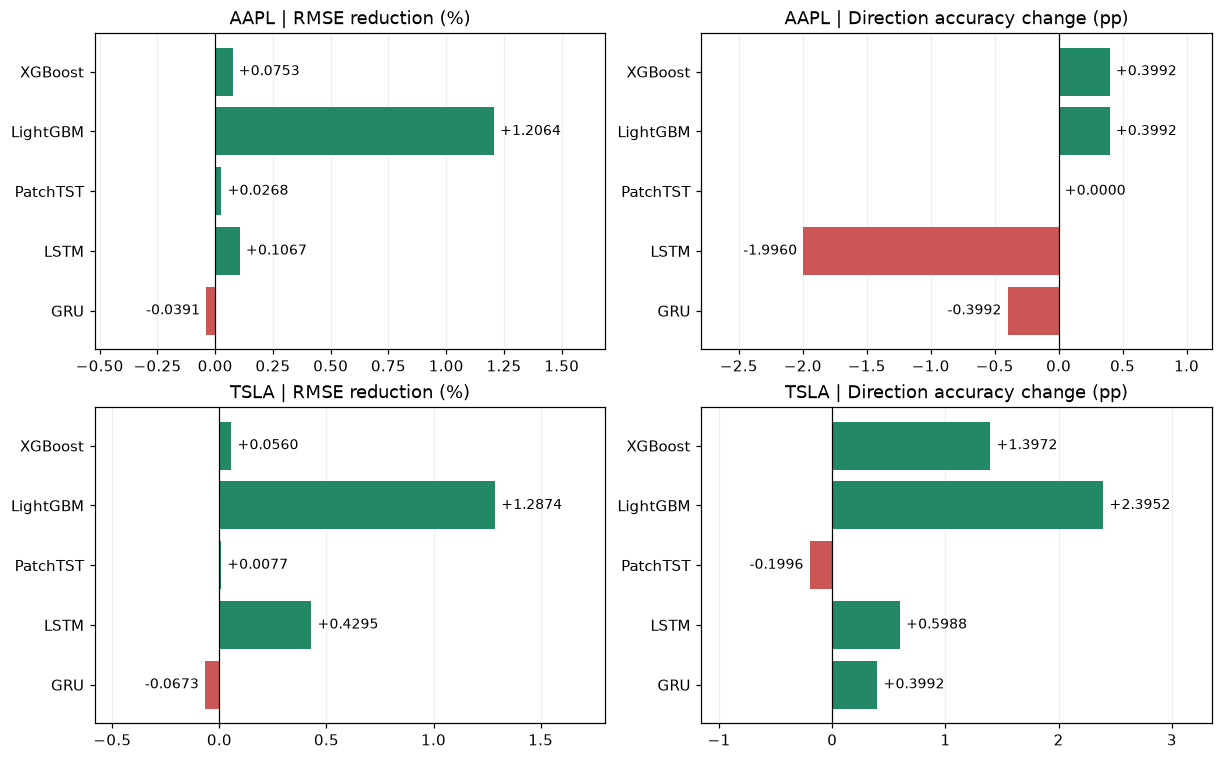

In [11]:
fig, axes = plt.subplots(len(pairs), 2, figsize=(11, 3.4*len(pairs)),
                         squeeze=False, layout='constrained')
specs = [('rmse_improvement_pct','RMSE reduction (%)'),
         ('direction_change_pp','Direction accuracy change (pp)')]
for i, (ticker, _, _) in enumerate(pairs):
    data = comparison[comparison.stock == ticker].set_index('model').loc[MODELS]
    for j, (metric, label) in enumerate(specs):
        ax = axes[i,j]
        values = data[metric].to_numpy(dtype=float)
        colors = ['#228866' if v > 1e-12 else '#CC5555' if v < -1e-12 else '#888888' for v in values]
        bars = ax.barh([LABELS[m] for m in MODELS], values, color=colors)
        ax.bar_label(bars, labels=[f'{v:+.4f}' for v in values], padding=4, fontsize=9)
        ax.axvline(0, color='black', linewidth=.8)
        span = max(float(np.nanmax(np.abs(values))), .001)
        ax.set_xlim(min(0,float(np.nanmin(values)))-.4*span,
                    max(0,float(np.nanmax(values)))+.4*span)
        ax.invert_yaxis()
        ax.set_title(f'{ticker} | {label}')
        ax.grid(axis='x', alpha=.2)
        ax.set_axisbelow(True)
plt.show()
plt.close(fig)